In [1]:
from pathlib import Path

from CITNP.utils.datautils import MultipleFileDataset


work_dir = Path(
    "/vol/bitbucket/ad6013/Research/CausalInferenceNeuralProcess/CITNP"
)

data_dir = work_dir / "datasets/synth_training_data" / "anticausal_simplegplvm_['ER']_2_1000"

In [2]:
val_dir = data_dir / "val"
val_files = list(val_dir.iterdir())
val_dataset = MultipleFileDataset([i for i in val_files if i.suffix == ".hdf5"])

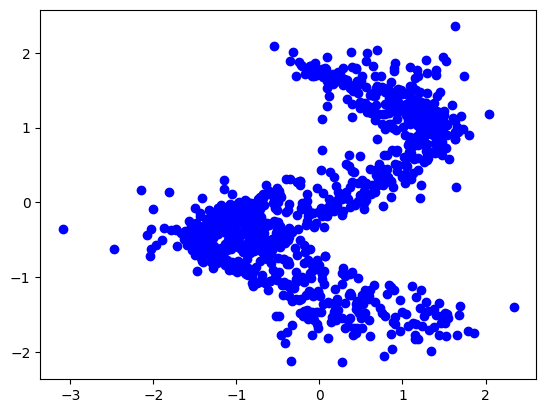

In [3]:
def get_single_dataset(dataset, index):
    """
    Get a single dataset from the MultipleFileDataset.
    """
    data = dataset[index]
    return data


import matplotlib.pyplot as plt
import numpy as np

for i in range(80, 81):
    data = get_single_dataset(val_dataset, i)
    (
        obs_data,
        int_data,
        causal_graph,
        intvn_indices,
        variable_counts,
        masks
    ) = data

    plt.scatter(
        obs_data[:, 0],
        obs_data[:, 1],
        c="blue",
        label="Observed Data"
    )
    # plt.scatter(
    #     int_data[:, 0],
    #     int_data[:, 1],
    #     c="red",
    #     label="Interventional Data"
    # )
    plt.show()
    plt.close()

In [4]:
obs_data.shape

(1000, 2)

In [5]:
int_data.shape

(1000, 2)

Epoch [1/2000] Train Loss: 34.3692 | Val Loss: 17.8125
Epoch [2/2000] Train Loss: 13.8549 | Val Loss: 17.4581
Epoch [3/2000] Train Loss: 10.4931 | Val Loss: 13.4363
Epoch [4/2000] Train Loss: 7.8205 | Val Loss: 8.4409
Epoch [5/2000] Train Loss: 6.4606 | Val Loss: 7.1398
Epoch [6/2000] Train Loss: 4.1585 | Val Loss: 2.9213
Epoch [7/2000] Train Loss: 1.9516 | Val Loss: 1.6267
Epoch [8/2000] Train Loss: 1.2841 | Val Loss: 1.6016
Epoch [9/2000] Train Loss: 1.0801 | Val Loss: 1.0124
Epoch [10/2000] Train Loss: 0.7103 | Val Loss: 0.7661
Epoch [11/2000] Train Loss: 0.6221 | Val Loss: 0.6857
Epoch [12/2000] Train Loss: 0.6782 | Val Loss: 0.8015
Epoch [13/2000] Train Loss: 0.5633 | Val Loss: 0.6561
Epoch [14/2000] Train Loss: 0.5113 | Val Loss: 0.5659
Epoch [15/2000] Train Loss: 0.4515 | Val Loss: 0.5784
Epoch [16/2000] Train Loss: 0.4518 | Val Loss: 0.6356
Epoch [17/2000] Train Loss: 0.4315 | Val Loss: 0.5950
Epoch [18/2000] Train Loss: 0.4238 | Val Loss: 0.8151
Epoch [19/2000] Train Loss: 0.5

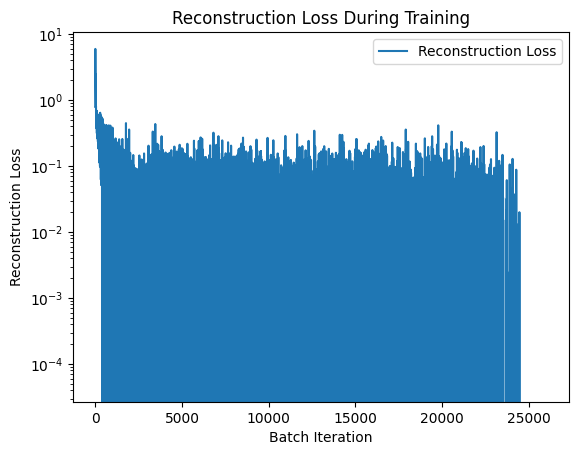

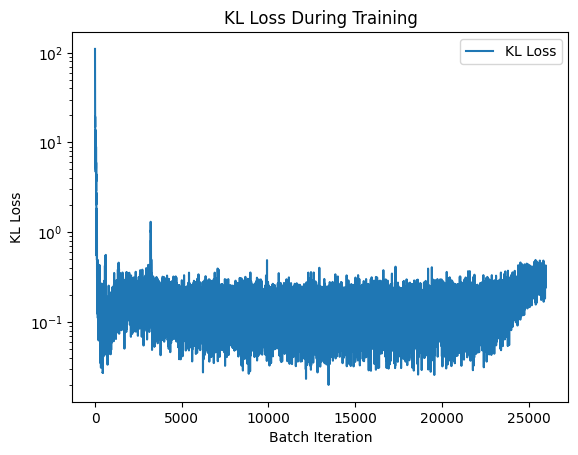

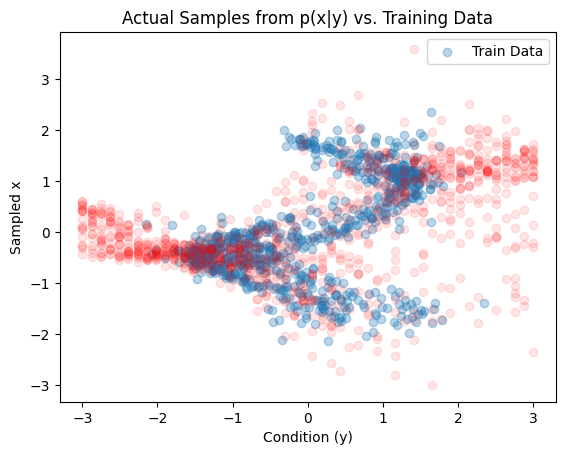

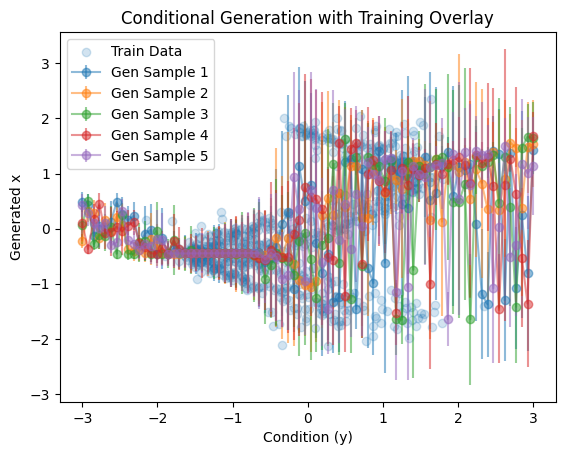

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import matplotlib.pyplot as plt


###############################################################################
class ResidualBlock(nn.Module):
    def __init__(self, dim):
        super(ResidualBlock, self).__init__()
        self.layer1 = nn.Linear(dim, dim)
        self.relu   = nn.ReLU()
        self.layer2 = nn.Linear(dim, dim)

    def forward(self, x):
        out = self.layer1(x)
        out = self.relu(out)
        out = self.layer2(out)
        return x + out


###############################################################################
# 1. The CVAE model (same multi-sample approach as before)
###############################################################################
class CVAE(nn.Module):
    def __init__(self,
                 x_dim,    # dimensionality of (continuous) target data x
                 y_dim,    # dimensionality of condition label y
                 z_dim=2,  # latent dimension
                 hidden_dim=128):
        super(CVAE, self).__init__()

        self.input_layer = nn.Linear(x_dim + y_dim, hidden_dim)
        # Encoder: maps [x, y] -> [z_mean, z_logvar]
        self.encoder = nn.ModuleList([
            ResidualBlock(hidden_dim) for _ in range(2)
        ])

        self.fc_mean   = nn.Linear(hidden_dim, z_dim)
        self.fc_logvar = nn.Linear(hidden_dim, z_dim)

        # Decoder: maps [z, y] -> [mean(x), log_var(x)]
        # Output 2*x_dim: mean and log-variance for x
        self.decoder = nn.Sequential(
            nn.Linear(z_dim + y_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
        )
        self.final_layer = nn.Linear(hidden_dim, 2 * x_dim)
        self._init_weights()


    def _init_weights(self):
        """
        Applies He/Kaiming initialization to all Linear layers
        . Also sets a small initialization for
        fc_mean and fc_logvar.
        """
     # 1) For encoder input and residual blocks
        def kaiming_init_linear(linear_layer):
            nn.init.kaiming_normal_(linear_layer.weight, nonlinearity='relu')
            if linear_layer.bias is not None:
                nn.init.zeros_(linear_layer.bias)

        # a) input_layer
        kaiming_init_linear(self.input_layer)

        # b) residual blocks
        for block in self.encoder:
            kaiming_init_linear(block.layer1)
            block.layer2.weight.data[:] = 0

        # c) final fc_mean, fc_logvar => small initialization
        nn.init.normal_(self.fc_mean.weight, mean=0.0, std=1e-2)
        nn.init.zeros_(self.fc_mean.bias)

        nn.init.normal_(self.fc_logvar.weight, mean=0.0, std=1e-2)
        # We'll bias logvar slightly negative => smaller initial variance
        nn.init.constant_(self.fc_logvar.bias, -1.0)

        # 2) For decoder
        for module in self.decoder:
            if isinstance(module, nn.Linear):
                kaiming_init_linear(module)

        kaiming_init_linear(self.final_layer)

    def encode(self, x, y):
        # 1) Input linear
        h = self.input_layer(torch.cat([x, y], dim=1))
        h = nn.functional.relu(h)

        # 2) Pass through each residual block
        for block in self.encoder:
            h = block(h)
            # Usually we apply ReLU after each block for VAEs:
            h = nn.functional.relu(h)

        # 3) Output z_mean, z_logvar
        z_mean = self.fc_mean(h)
        z_logvar = self.fc_logvar(h)  # log(sigma_z^2)
        return z_mean, z_logvar

    def reparameterize(self, mean, logvar):
        std = torch.exp(0.5 * logvar)  # sigma_z
        eps = torch.randn_like(std)
        return mean + eps * std

    def decode(self, z, y):
        dec_input = torch.cat([z, y], dim=1)
        out = self.final_layer(
            self.decoder(dec_input)
        )
        # Split into mean and log-variance for x
        x_dim_out = out.size(1) // 2
        x_mean    = out[:, :x_dim_out]
        x_logvar  = out[:, x_dim_out:]
        return x_mean, x_logvar

    def forward(self, x, y, n_samples=1):
        """
        Multi-sample forward pass.

        Returns:
            x_mean:   [batch_size, n_samples, x_dim]
            x_logvar: [batch_size, n_samples, x_dim]
            z_mean:   [batch_size, z_dim]
            z_logvar: [batch_size, z_dim]
        """
        batch_size = x.size(0)
        z_mean, z_logvar = self.encode(x, y)

        if n_samples > 1:
            # Expand (z_mean, z_logvar) for multiple samples
            z_mean_exp   = z_mean.unsqueeze(1).repeat(1, n_samples, 1)
            z_logvar_exp = z_logvar.unsqueeze(1).repeat(1, n_samples, 1)
            eps = torch.randn_like(z_mean_exp)
            z = z_mean_exp + eps * torch.exp(0.5 * z_logvar_exp)  # [B, n_samples, z_dim]

            # Repeat y similarly
            y_exp = y.unsqueeze(1).repeat(1, n_samples, 1)  # [B, n_samples, y_dim]

            # Flatten for a single decode pass
            z_flat = z.view(batch_size * n_samples, -1)
            y_flat = y_exp.view(batch_size * n_samples, -1)

            x_mean_flat, x_logvar_flat = self.decode(z_flat, y_flat)
            x_mean   = x_mean_flat.view(batch_size, n_samples, -1)
            x_logvar = x_logvar_flat.view(batch_size, n_samples, -1)
        else:
            # Single-sample path
            z = self.reparameterize(z_mean, z_logvar)
            x_mean_single, x_logvar_single = self.decode(z, y)
            x_mean   = x_mean_single.unsqueeze(1)   # [B, 1, x_dim]
            x_logvar = x_logvar_single.unsqueeze(1) # [B, 1, x_dim]

        return x_mean, x_logvar, z_mean, z_logvar


###############################################################################
# 2. Loss: Gaussian NLL + KL
###############################################################################
def gaussian_nll(x, x_mean, x_logvar):
    """
    x: [batch_size, x_dim]
    x_mean, x_logvar: [batch_size, n_samples, x_dim]

    We'll compute the NLL for each sample, then average over n_samples & batch.
    """
    # Expand x to [batch_size, 1, x_dim] for broadcasting
    x_expanded = x.unsqueeze(1)  # [B, 1, x_dim]
    mse_term   = (x_expanded - x_mean)**2 / torch.exp(x_logvar)
    # Summation across x_dim => shape [B, n_samples]
    nll_per_sample = 0.5 * torch.sum(x_logvar + mse_term, dim=2)
    # Mean over samples and batch => scalar
    return torch.mean(nll_per_sample)


def cvae_loss_function(x, x_mean, x_logvar, z_mean, z_logvar):
    """
    - x: [B, x_dim]
    - x_mean, x_logvar: [B, n_samples, x_dim]
    - z_mean, z_logvar: [B, z_dim]
    """
    # 1) Reconstruction
    recon_loss = gaussian_nll(x, x_mean, x_logvar)

    # 2) KL
    # KL_i = 0.5 * sum(exp(logvar_z) + mean_z^2 - 1 - logvar_z), sum over z_dim
    kl_i   = 0.5 * torch.sum(torch.exp(z_logvar) + z_mean**2 - 1.0 - z_logvar, dim=1)
    kl_loss = torch.mean(kl_i)  # average over batch
    return recon_loss + kl_loss, recon_loss, kl_loss


###############################################################################
# 3. Train with multi-sample
###############################################################################
def train_cvae(model, train_loader, val_loader, n_samples=1, num_epochs=10, lr=1e-3, device='cpu'):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    model.to(device)
    model.train()

    all_recon_loss = []
    all_kl_loss = []

    for epoch in range(num_epochs):
        model.train()
        total_train_loss = 0.0

        for x_batch, y_batch in train_loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            x_mean, x_logvar, z_mean, z_logvar = model(x_batch, y_batch, n_samples=n_samples)
            loss, recon_loss, kl_loss = cvae_loss_function(x_batch, x_mean, x_logvar, z_mean, z_logvar)
            loss.backward()
            optimizer.step()

            all_recon_loss.append(recon_loss.item())
            all_kl_loss.append(kl_loss.item())

            total_train_loss += loss.item() * x_batch.size(0)

        # Validation
        model.eval()
        total_val_loss = 0.0
        with torch.no_grad():
            for x_val, y_val in val_loader:
                x_val = x_val.to(device)
                y_val = y_val.to(device)
                x_mean, x_logvar, z_mean, z_logvar = model(x_val, y_val, n_samples=n_samples)
                val_loss, _, _ = cvae_loss_function(x_val, x_mean, x_logvar, z_mean, z_logvar)
                total_val_loss += val_loss.item() * x_val.size(0)

        avg_train_loss = total_train_loss / len(train_loader.dataset)
        avg_val_loss   = total_val_loss / len(val_loader.dataset)
        print(f"Epoch [{epoch+1}/{num_epochs}] "
              f"Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")
    # 1) Plot Reconstruction Loss
    plt.figure()
    plt.plot(all_recon_loss, label='Reconstruction Loss')
    plt.xlabel('Batch Iteration')
    plt.ylabel('Reconstruction Loss')
    plt.yscale('log')  # Log-scale on the y-axis
    plt.title('Reconstruction Loss During Training')
    plt.legend()
    plt.show()

    # 2) Plot KL Loss
    plt.figure()
    plt.plot(all_kl_loss, label='KL Loss')
    plt.xlabel('Batch Iteration')
    plt.ylabel('KL Loss')
    plt.yscale('log')  # Log-scale on the y-axis
    plt.title('KL Loss During Training')
    plt.legend()
    plt.show()


###############################################################################
# 4. Evaluate function returning multi-sample predictions
###############################################################################
def evaluate_cvae(model, X, Y, n_samples=1, device='cpu'):
    """
    Returns:
      x_means:   [N, n_samples, x_dim]
      x_stds:    [N, n_samples, x_dim]
    for each data point in (X, Y).
    """
    model.eval()
    X = X.to(device)
    Y = Y.to(device)

    with torch.no_grad():
        x_mean, x_logvar, _, _ = model(X, Y, n_samples=n_samples)
        x_std = torch.exp(0.5 * x_logvar)

    return x_mean.cpu().numpy(), x_std.cpu().numpy()


###############################################################################
# 5. Conditional generation from prior with multi-samples
###############################################################################
def sample_from_condition(model, y, n_samples=1, device='cpu'):
    """
    Draws random z ~ N(0,I), decodes to get (x_mean, x_logvar),
    then samples x ~ N(x_mean, exp(x_logvar)).

    Returns x_samples with shape [batch_size, n_samples, x_dim].
    """
    model.eval()
    y = y.to(device)
    batch_size = y.size(0)

    z_dim = model.fc_mean.out_features
    # Sample z from prior p(z) = N(0, I)
    z = torch.randn(batch_size, n_samples, z_dim, device=device)
    # Expand y
    y_exp = y.unsqueeze(1).repeat(1, n_samples, 1)  # [B, n_samples, y_dim]

    # Flatten for decoding
    z_flat = z.view(batch_size * n_samples, -1)
    y_flat = y_exp.view(batch_size * n_samples, -1)

    with torch.no_grad():
        x_mean_flat, x_logvar_flat = model.decode(z_flat, y_flat)
        x_std_flat = torch.exp(0.5 * x_logvar_flat)

        # Sample x ~ N(x_mean, sigma^2)
        eps = torch.randn_like(x_mean_flat)  # same shape
        x_samples_flat = x_mean_flat + eps * x_std_flat

    # Reshape back to [batch_size, n_samples, x_dim]
    x_samples = x_samples_flat.view(batch_size, n_samples, -1)
    return x_samples.cpu().numpy()


def generate_from_condition(model, y, n_samples=1, device='cpu'):
    """
    For each data point in y, we sample 'n_samples' from the prior p(z).
    Returns x_means, x_stds with shape [batch_size, n_samples, x_dim].
    """
    model.eval()
    y = y.to(device)
    batch_size = y.size(0)

    z_dim = model.fc_mean.out_features
    z = torch.randn(batch_size, n_samples, z_dim, device=device)
    y_exp = y.unsqueeze(1).repeat(1, n_samples, 1)  # match shape for decoding

    z_flat = z.view(batch_size * n_samples, z_dim)
    y_flat = y_exp.view(batch_size * n_samples, -1)

    with torch.no_grad():
        x_mean_flat, x_logvar_flat = model.decode(z_flat, y_flat)
    x_std_flat = torch.exp(0.5 * x_logvar_flat)

    x_mean = x_mean_flat.view(batch_size, n_samples, -1)
    x_std  = x_std_flat.view(batch_size, n_samples, -1)

    return x_mean.cpu().numpy(), x_std.cpu().numpy()

###############################################################################
# 6. Putting it all together: Example usage
###############################################################################
if __name__ == "__main__":

    N = 1000
    y_vals = obs_data[:, 0]  # shape [N,1]
    x_vals = obs_data[:, 1]  # shape [N,1]

    obs_data_full = np.column_stack([x_vals, y_vals])  # shape [1000, 2]

    # Convert to torch Tensors
    obs_data_t = torch.from_numpy(obs_data_full).float()  # [N,2]
    # X is first column (regression target), Y is second column (condition)
    X = obs_data_t[:, 0:1]  # shape [N,1]
    Y = obs_data_t[:, 1:2]  # shape [N,1]

    # Train/val split
    split_idx = int(0.8 * N)
    X_train, Y_train = X[:split_idx], Y[:split_idx]
    X_val,   Y_val   = X[split_idx:], Y[split_idx:]

    # Create DataLoaders
    train_dataset = TensorDataset(X_train, Y_train)
    val_dataset   = TensorDataset(X_val, Y_val)
    train_loader  = DataLoader(train_dataset, batch_size=64, shuffle=True)
    val_loader    = DataLoader(val_dataset, batch_size=64, shuffle=False)

    # ------------------------------------------------------------------------
    # (B) Instantiate & Train with multi-sample
    # ------------------------------------------------------------------------
    x_dim = 1
    y_dim = 1
    latent_dim = 512
    hidden_dim = 512

    model = CVAE(x_dim, y_dim, z_dim=latent_dim, hidden_dim=hidden_dim)
    train_cvae(model, train_loader, val_loader,
               n_samples=16,  # multiple z-samples per data point
               num_epochs=2000,
               lr=1e-3,
               device='cpu')

    # ------------------------------------------------------------------------
    # (C) Evaluate on training & validation sets with multiple samples
    #     We then plot the (x_mean, x_std) for each sample
    # ------------------------------------------------------------------------
    n_plot_samples = 20  # how many samples to draw for each y
    y_grid = torch.linspace(-3, 3, steps=50).unsqueeze(1)  # shape [50,1]

    # Use our new function sample_from_condition(...) to get actual x samples
    x_samples = sample_from_condition(model, y_grid, n_samples=n_plot_samples, device='cpu')
    # x_samples shape: [50, n_plot_samples, 1]

    # We'll also get training data for overlay
    x_train_np = X_train.squeeze().numpy()  # shape [N_train]
    y_train_np = Y_train.squeeze().numpy()

    ############################################################################
    # (F) Plot
    ############################################################################
    y_grid_np = y_grid.squeeze().numpy()   # shape [50]
    plt.figure()
    plt.scatter(y_train_np, x_train_np, alpha=0.3, label="Train Data")

    # For each y in the grid, we have many draws of x. We'll scatter them:
    for i, y_val in enumerate(y_grid_np):
        # x_samples[i] has shape [n_plot_samples, 1]
        # We'll broadcast y_val into that many points
        y_points = np.full(shape=(n_plot_samples,), fill_value=y_val)
        x_points = x_samples[i, :, 0]
        # Plot at alpha=0.1 so it doesn't get too dense
        plt.scatter(y_points, x_points, alpha=0.1, color="red")

    plt.title("Actual Samples from p(x|y) vs. Training Data")
    plt.xlabel("Condition (y)")
    plt.ylabel("Sampled x")
    plt.legend()
    plt.show()

    y_grid = torch.linspace(-3, 3, steps=80).unsqueeze(1)
    n_gen_samples = 5
    gen_mean, gen_std = generate_from_condition(model, y_grid, n_samples=n_gen_samples)
    y_grid_np = y_grid.squeeze().numpy()

    plt.figure()
    # Plot training set overlay
    plt.scatter(y_train_np, x_train_np, alpha=0.2, label="Train Data")
    # For each generated sample, plot error bars showing mean +/- 2*std
    for s in range(n_gen_samples):
        mean_s = gen_mean[:, s, 0]  # shape [num_points]
        std_s  = gen_std[:, s, 0]

        # 'yerr=2*std_s' will draw the error bars
        # 'fmt' controls the marker/line style (can set to 'o-', etc.)
        plt.errorbar(
            y_grid_np,
            mean_s,
            yerr=2*std_s,
            fmt='-o',        # line with circular markers
            alpha=0.5,       # transparency
            label=f"Gen Sample {s+1}"
        )

    plt.title("Conditional Generation with Training Overlay")
    plt.xlabel("Condition (y)")
    plt.ylabel("Generated x")
    plt.legend()
    plt.show()


In [ ]:
np.exp(0.5 * 0)

np.float64(1.0)

: 

In [ ]:
y_grid.shape

torch.Size([50, 1])

: 

In [ ]:

obs_data.std(0)

array([0.71291538, 0.57792791])

: 

: 